In [1]:
pip install -U mplhep

  Using cached mplhep-1.3.3-py3-none-any.whl.metadata (9.5 kB)


  Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)


Using cached mplhep-1.3.3-py3-none-any.whl (93 kB)
Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (9.9 MB)


  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.8
    Uninstalling matplotlib-3.10.8:


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [matplotlib]

...

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [matplotlib]

  Attempting uninstall: mplhep
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [matplotlib]

    Found existing installation: mplhep 1.1.2
    Uninstalling mplhep-1.1.2:
      Successfully uninstalled mplhep-1.1.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [matplotlib]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [mplhep]


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys
sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)
from sidm.tools import utilities #scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions
utilities.set_plot_style()

In [9]:

ratio = 1
sum_hist={}

channels = ["cr_Zmumu",
    "cr_Zmumu_noLJ",
           "cr_Zmumu_noLJ_highPtId", 
           "cr_Zmumu_noLJ_noMu_cut"]

DY = functions.get_bg_file_names("DYJetsToLL")

for channel_name in channels:

    folder_name = f"OutputFiles/{channel_name}"
    summed_DY  = utilities.sum_hist(DY, folder_name)
    sum_hist[channel_name] = summed_DY
# 


In [10]:
X =sum_hist["cr_Zmumu_noLJ_highPtId"].keys()
Y =sum_hist["cr_Zmumu_noLJ"].keys()
print(X-Y)
print(Y-X)

set()
{'mu0_mu1_dR_vs_mu_lj_mass', 'mu0_mu1_dR_vs_dimuon_mass'}


In [11]:
# keys=sum_hist["cr_Zmumu_noLJ"].keys()
keys = list(Y-X) + ["muon_n"]

mu0_mu1_dR_vs_mu_lj_mass
skipping mu0_mu1_dR_vs_mu_lj_mass
skipping mu0_mu1_dR_vs_mu_lj_mass


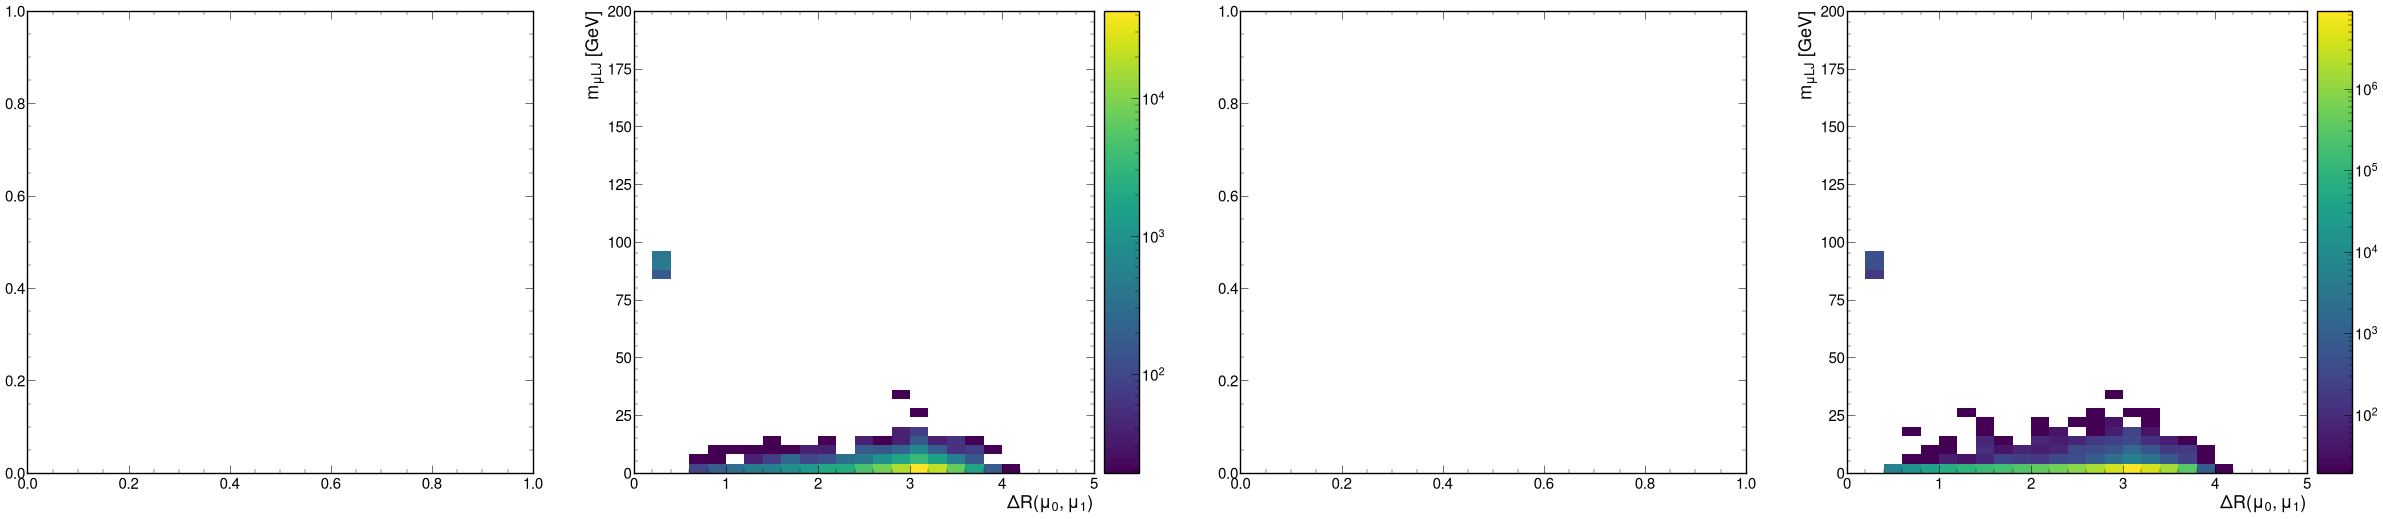

mu0_mu1_dR_vs_dimuon_mass
skipping mu0_mu1_dR_vs_dimuon_mass
skipping mu0_mu1_dR_vs_dimuon_mass


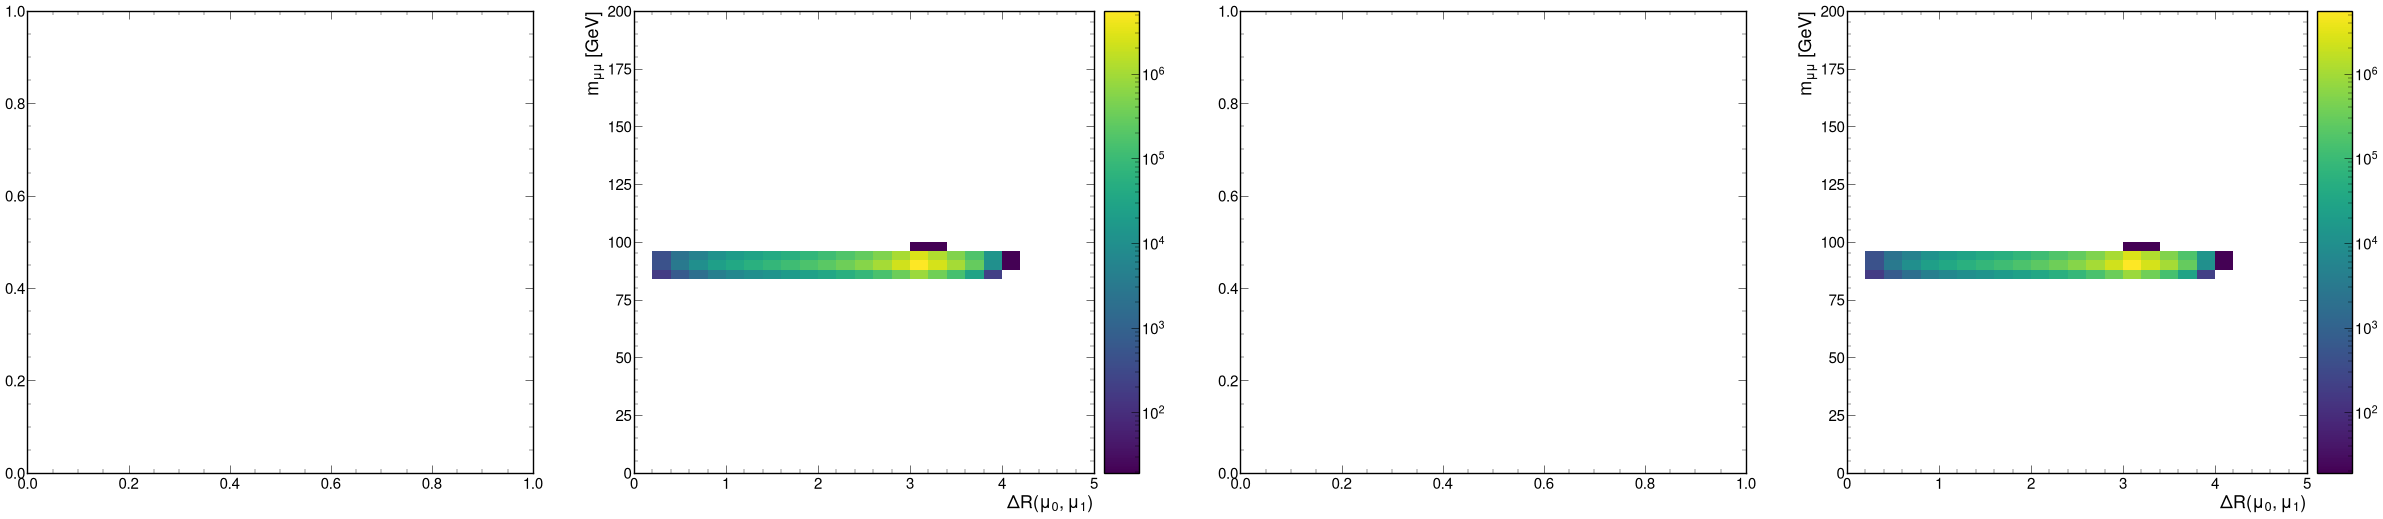

muon_n


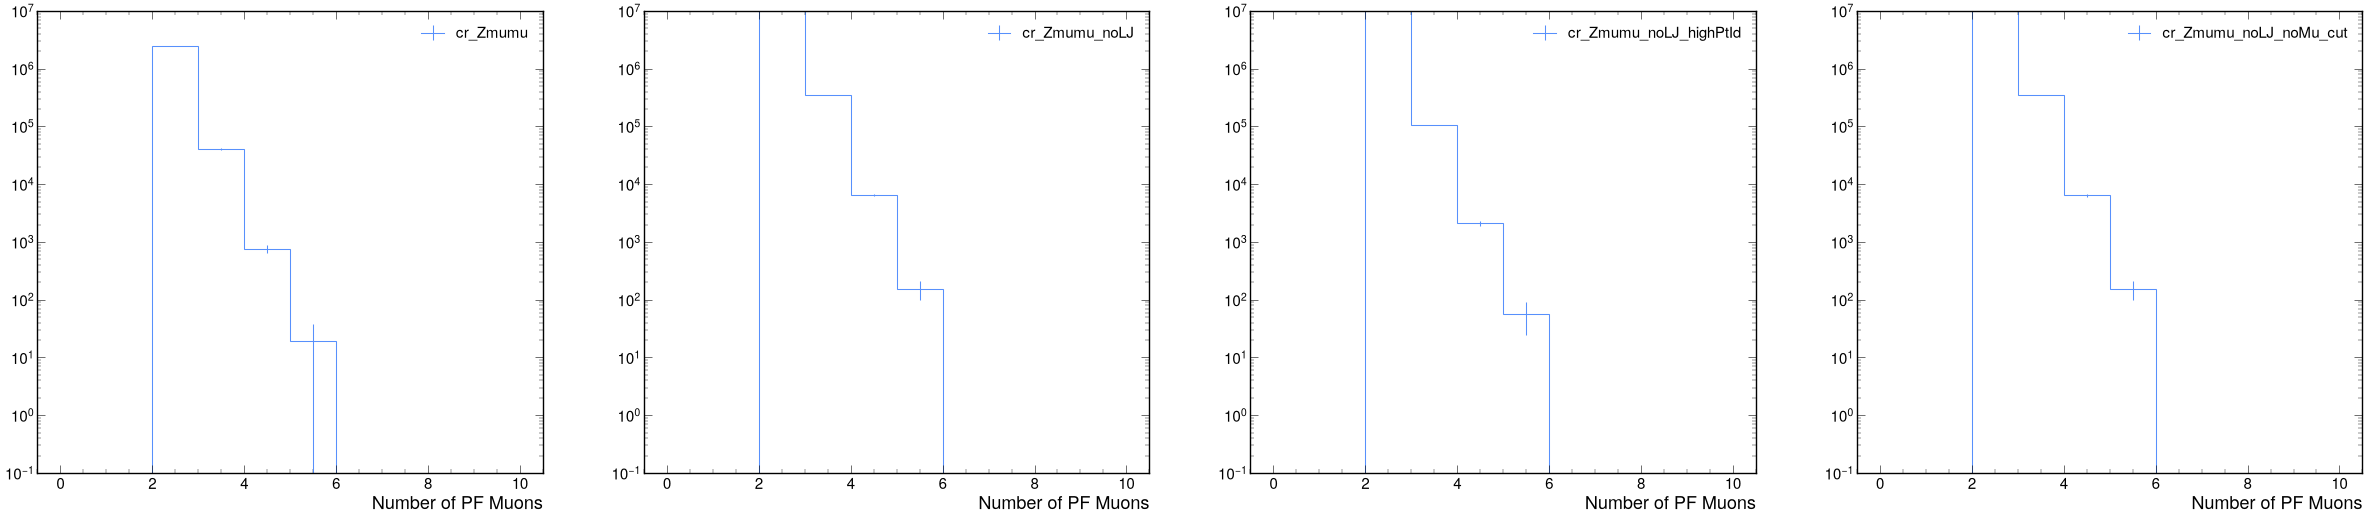

In [12]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
n=  len(channels)
for i, histogram_name in  enumerate(keys):
    print(histogram_name)
    fig, axs =  plt.subplots(1,n, figsize=(n*15, 12))
    for j, channel_name in enumerate(channels):
        ax = axs[j]
        try:
            histogram = sum_hist[channel_name][histogram_name][channel_name, :]
            utilities.plot(histogram, ax=ax, label=channel_name, skip_label=True)
            ax.legend()
            ax.set_yscale("log")
            ax.set_ylim(1e-1, 1e7)
        except:
            try:
                histogram = sum_hist[channel_name][histogram_name][channel_name, ::2j, ::2j]
                utilities.plot(histogram, ax=ax, label=channel_name, skip_label=True, norm=LogNorm())
            except:
                print(f"skipping {histogram_name}")
                continue

        
    plt.show()
    plt.close()